# Transmission through the thin 26-hole device

## Original 1 GHz mesh comparison

The 100 nm thick germanium device is driven from the left on **incident slot 3** of the 225 nm mesh. Signed port displacement matches track that mode across the finer meshes. The original reference planes are **x = 0 and 16.65 µm**.

Transmission and reflection each sum the power in the five outgoing propagating channels, as a percentage of the incident power. Each mesh uses two quadratic thickness layers, the same leads, and the same 32-segment hole rims.

| Central edge ceiling (nm) | Incident slot | Matched root | Assembled on | Solved on | T (%) | R (%) | Source |
|---:|---:|---:|---|---|---:|---:|---|
| 225 | 3 | 258 | Windows | Windows | 30.5660 | 69.4340 | [Native CSV](thin100_central400_edge225_rim32/scattering_map_AP_pnc.csv) |
| 168.75 | 3 | 258 | Windows | Lawrence Linux | 43.9553 | 56.0447 | [Native CSV](thin100_central400_edge168p75_rim32_linux/scattering_map_AP_pnc.csv) |
| 126.5625 | 3 | 258 | Lawrence Linux | Lawrence Linux | 59.8453 | 40.1547 | [Native CSV](thin100_central400_edge126p5625_rim32_linux/scattering_map_AP_pnc.csv) |


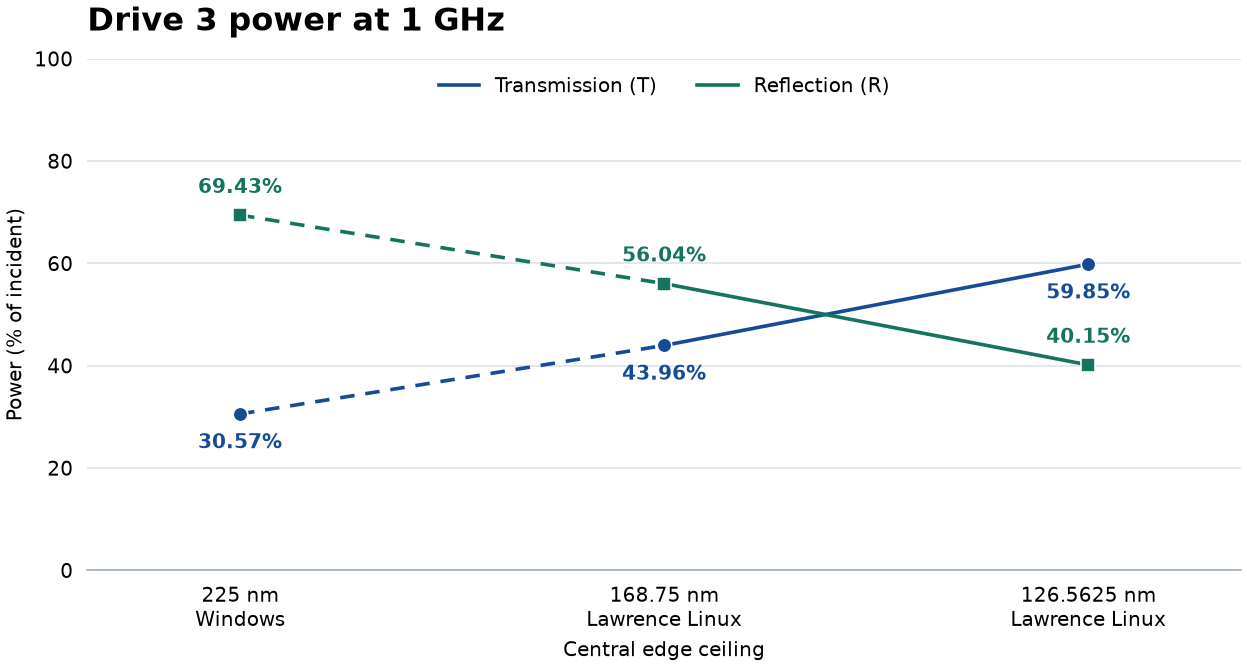

In [1]:
import matplotlib.pyplot as plt

# Central edge ceiling (nm), solve host, transmitted and reflected fractions.
levels = [
    (225, 'Windows', 0.305659962248429, 0.6943400377515528),
    (168.75, 'Lawrence Linux', 0.4395534821700408, 0.5604465178300051),
    (126.5625, 'Lawrence Linux', 0.5984533528477504, 0.40154664715228494),
]

x = range(len(levels))
fig, ax = plt.subplots(figsize=(8.6, 4.6), layout="constrained", facecolor="white")
for column, label, color, marker, offset in (
    (2, "Transmission (T)", "#164b98", "o", -17),
    (3, "Reflection (R)", "#14745f", "s", 11),
):
    power_pct = [row[column] * 100 for row in levels]
    ax.plot(x[:2], power_pct[:2], color=color, linewidth=1.8, linestyle=(0, (4, 3)))
    ax.plot(x[1:], power_pct[1:], color=color, linewidth=1.8, label=label)
    ax.scatter(x, power_pct, color=color, marker=marker, s=52, edgecolors="white", linewidths=0.8, zorder=3)
    for index, power in zip(x, power_pct):
        ax.annotate(f"{power:.2f}%", (index, power), xytext=(0, offset),
                    textcoords="offset points", ha="center", fontsize=10,
                    color=color, fontweight="bold")

ax.set(xlabel="Central edge ceiling", ylabel="Power (% of incident)", ylim=(0, 100), xlim=(-0.36, 2.36))
ax.set_xticks(list(x), [f"{row[0]:.7g} nm\n{row[1]}" for row in levels])
ax.set_yticks(range(0, 101, 20))
ax.set_title("Drive 3 power at 1 GHz", loc="left", fontsize=16, weight="bold", pad=14)
ax.grid(axis="y", color="#dbe2e8", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color("#9cacba")
ax.tick_params(axis="both", length=0, pad=7)
ax.legend(loc="upper center", ncols=2, frameon=False)
plt.show()


Drive 3 transmission changes by **+13.39** and **+15.89 percentage points** in the two steps. The last change exceeds the **1 percentage point** absolute power gate for this drive. The dashed segment includes the move from Windows to Linux solving. Lawrence Linux was used for both finer solves. The 168.75 nm operators were assembled on Windows, and the 126.5625 nm operators were assembled on Linux. These are finite comparisons at one frequency.

[Verified 1 GHz channel comparison](../../../verification/thin_device_nested_response_AP_pnc.json) · Athul Prem | athul_simulation_pnc_thin100_1GHz_mesh_response

In [2]:
from pathlib import Path
import json

record_path = Path("verification/thin_device_layer_response_AP_pnc.json")
working_dir = Path.cwd()
for folder in (working_dir, *working_dir.parents):
    if (folder / record_path).is_file():
        layer_response = json.loads((folder / record_path).read_bytes())
        break
else:
    raise FileNotFoundError(f"Open the notebook inside the project to load {record_path}.")

def show_layer_powers(footprint, levels):
    print(f"\n{footprint}")
    print(f"{'Layers':>6} {'Slot':>5} {'Root':>5} {'T (%)':>10} {'R (%)':>10}")
    for layer, level in levels.items():
        drive = level["native_drive"]
        print(f"{layer:>6} {drive['drive']:>5} {drive['native_root_id']:>5} "
              f"{100 * drive['transmission']:>10.4f} {100 * drive['reflection']:>10.4f}")

def show_layer_change(label, change):
    print(f"{label}  ΔT {change['T']:+.4f} pp   ΔR {change['R']:+.4f} pp")

planes_um = [1e6 * x for x in layer_response["reference_planes_x_m"]]
print(f"Matched drive at {layer_response['frequency_hz'] / 1e9:g} GHz | "
      f"{layer_response['physical_thickness_nm']:g} nm Ge | "
      f"original planes x = {planes_um[0]:g} and {planes_um[1]:g} µm")
print("Total T and R are percentages of incident power. Body and port layers change together.")
parent_nm = layer_response["geometry_targets_nm"]["central"]
show_layer_powers(f"{parent_nm:g} nm parent central target", layer_response["levels"])
for step, increment in layer_response["increments"].items():
    show_layer_change(f"  {step.replace('_', ' ')} layers", increment["signed_change_percentage_points"])

central_control = layer_response.get("central_layer_control")
if central_control is not None:
    coarse = central_control["coarser_footprint"]
    coarse_nm = coarse["central_max_edge_nm"]
    show_layer_powers(f"{coarse_nm:.8g} nm fixed central edge ceiling", coarse["levels"])
    coarse_changes = central_control["three_minus_two_layer_increments"][f"{coarse_nm:g}"]
    show_layer_change("  2 to 3 layers", coarse_changes["signed_change_percentage_points"])

fine = layer_response.get("fine_footprint")
if fine is None:
    print("\nThe fine z2/z3 comparison is pending verified data.")
else:
    fine_nm = fine["central_max_edge_nm"]
    show_layer_powers(f"{fine_nm:.8g} nm fixed central edge ceiling", fine["levels"])
    show_layer_change("  2 to 3 layers", fine["increment_2_to_3"]["signed_change_percentage_points"])
    show_layer_change("  Fine minus parent layer increment", fine["fine_minus_parent_increment_percentage_points"])

gate_pp = 100 * layer_response["total_drive_power_change_limit"]
if central_control is None:
    central_step = layer_response["central_anchor"]["finest_central_T_increment_percentage_points"]
    print(f"\nPower increment limit {gate_pp:g} pp | Last in-plane T change {central_step:+.4f} pp")
else:
    fine_nm = central_control["finer_footprint_central_max_edge_nm"]
    print(f"\nCentral refinement from {coarse_nm:.8g} to {fine_nm:.8g} nm")
    for layer, increment in central_control["finer_minus_coarser_central_increments"].items():
        show_layer_change(f"  {layer} layers", increment["signed_change_percentage_points"])
    show_layer_change("  Three-layer minus two-layer increment",
                      central_control["finer_minus_coarser_layer_increment_percentage_points"])
    print(f"Power increment limit {gate_pp:g} pp. The 168.75 nm two-layer case used Windows assembly.")
    print("The other three cases used Linux assembly. All four used Linux solves.")
print(f"Source {record_path} | {layer_response['author']}")


Matched drive at 1 GHz | 100 nm Ge | original planes x = 0 and 16.65 µm
Total T and R are percentages of incident power. Body and port layers change together.

400 nm parent central target
Layers  Slot  Root      T (%)      R (%)
     1     3   148    86.8267    13.1733
     2     3   258    92.0266     7.9734
     3     3   364    94.5032     5.4968
  1 to 2 layers  ΔT +5.1998 pp   ΔR -5.1998 pp
  2 to 3 layers  ΔT +2.4766 pp   ΔR -2.4766 pp

168.75 nm fixed central edge ceiling
Layers  Slot  Root      T (%)      R (%)
     2     3   258    43.9553    56.0447
     3     3   364    48.6884    51.3116
  2 to 3 layers  ΔT +4.7331 pp   ΔR -4.7331 pp

126.5625 nm fixed central edge ceiling
Layers  Slot  Root      T (%)      R (%)
     2     3   258    59.8453    40.1547
     3     3   364    67.3021    32.6979
  2 to 3 layers  ΔT +7.4568 pp   ΔR -7.4568 pp
  Fine minus parent layer increment  ΔT +4.9801 pp   ΔR -4.9801 pp

Central refinement from 168.75 to 126.5625 nm
  2 layers  ΔT +15.89

In [3]:
from pathlib import Path
import json

patch_record_path = Path("verification/taper_patch_response_1GHz_AP_pnc.json")
working_dir = Path.cwd()
for folder in (working_dir, *working_dir.parents):
    if (folder / patch_record_path).is_file():
        patch_response = json.loads((folder / patch_record_path).read_bytes())
        break
else:
    raise FileNotFoundError(f"Open the notebook inside the project to load {patch_record_path}.")

coarse = patch_response["factorial_power_comparison"]
finer = patch_response["finer_center_comparison"]
drive3 = next(row for row in coarse["per_drive"] if row["reference_drive"] == 3)
trend = next(row for row in finer["central_refinement_trend"]["per_drive"] if row["reference_drive"] == 3)
edge = finer["increments"]["full_refinement_to_finer_center"]
matched_drive3 = next(row for row in edge["drive_power_fractions"]
                      if row["reference"]["native_root_id"] == trend["finer_step_incident_root"])
mean = coarse["equal_incoherent_mean_power_fractions"]["transmission"]
drive3_t = drive3["power_fractions"]["transmission"]
finer_mean = edge["equal_incoherent_mean_power_fractions"]

patch_planes_um = [1e6 * x for x in patch_response["reference_planes_x_m"]]
print("Regional mesh sensitivity")
print(f"{patch_response['physical_thickness_nm']:g} nm Ge | {patch_response['frequency_hz'] / 1e9:g} GHz | "
      f"original planes x = {patch_planes_um[0]:g} and {patch_planes_um[1]:g} µm")
print("Drive 3 follows the signed port match from the 225 nm baseline.")
print("Transmission sums five outgoing channels. The incoherent mean weights all five incident drives equally.")
print(f"\n{'Mesh control':<42} {'Drive 3 T (%)':>14} {'Mean T (%)':>12}")
for case, label in (
    ("baseline", "225 nm baseline"),
    ("taper_patch", "225 → 168.75 nm, taper/cavity only"),
    ("complement", "225 → 168.75 nm, complement only"),
    ("full_refinement", "225 → 168.75 nm, both regions"),
):
    print(f"{label:<42} {100 * drive3_t[case]:>14.4f} {100 * mean[case]:>12.4f}")
print(f"{'168.75 → 126.5625 nm, taper/cavity only':<42} "
      f"{100 * matched_drive3['candidate']['transmission']:>14.4f} "
      f"{100 * finer_mean['candidate']['transmission']:>12.4f}")

effects = drive3["signed_effects_percentage_points"]["transmission"]
mean_effects = coarse["signed_equal_incoherent_mean_effects_percentage_points"]["transmission"]
print(f"\n{'Transmission change (percentage points)':<42} {'Drive 3':>14} {'Mean':>12}")
for label, step in (
    ("225 → 168.75 nm, taper/cavity only", "central_at_coarse_exterior"),
    ("225 → 168.75 nm, mixed difference", "mixed_difference"),
):
    print(f"{label:<42} {effects[step]:>+14.4f} {mean_effects[step]:>+12.4f}")
print(f"{'168.75 → 126.5625 nm, taper/cavity only':<42} "
      f"{matched_drive3['candidate_minus_reference_percentage_points']['transmission']:>+14.4f} "
      f"{finer_mean['candidate_minus_reference_percentage_points']['transmission']:>+12.4f}")
print("\nThe mixed difference measures how refining the complement changes the taper/cavity increment.")
print("The finer taper/cavity step keeps the 168.75 nm exterior mesh. Spatial and frequency convergence remain unresolved.")
print(f"Source {patch_record_path} | {patch_response['author']}")


Regional mesh sensitivity
100 nm Ge | 1 GHz | original planes x = 0 and 16.65 µm
Drive 3 follows the signed port match from the 225 nm baseline.
Transmission sums five outgoing channels. The incoherent mean weights all five incident drives equally.

Mesh control                                Drive 3 T (%)   Mean T (%)
225 nm baseline                                   30.5660      70.7481
225 → 168.75 nm, taper/cavity only                40.7422      74.9297
225 → 168.75 nm, complement only                  29.5826      70.3391
225 → 168.75 nm, both regions                     43.9553      76.2096
168.75 → 126.5625 nm, taper/cavity only           56.7291      81.2730

Transmission change (percentage points)           Drive 3         Mean
225 → 168.75 nm, taper/cavity only               +10.1762      +4.1816
225 → 168.75 nm, mixed difference                 +4.1966      +1.6889
168.75 → 126.5625 nm, taper/cavity only          +12.7738      +5.0634

The mixed difference measures how refi

## Three sampled frequencies on fixed-facet meshes

The 100 nm device uses two quadratic thickness layers and the same 32-segment hole rims, leads, and reference planes at x = 0 and 16.65 µm. The central edge target is the resolution changed here. Drive 3 and drive 5 follow signed displacement matches from the 225 nm mesh at 1000 MHz. The mean weights five mutually incoherent incident drives equally.

Markers show the accepted 995, 997.5 and 1000 MHz samples. Line segments join the saved values and each panel has its own vertical scale. The summary checks the transmission power per drive and complex scattering amplitudes on each adjacent mesh step. Spatial and frequency convergence remain unresolved.

The plot sums each native input's channel powers from 450 complex coefficient rows. The cell checks the six original map publications and CSV hashes, then cross-checks all drive powers against the matched comparison.

[Verified mesh and frequency comparison](../../../verification/thin_mesh_frequency_AP_pnc.json)


Verified 450 complex coefficient rows from 6 native maps.
Spatial transmission limit 1 percentage point per drive. 0 of 6 adjacent-mesh comparisons pass across all five drives. The largest observed drive change is 15.890 percentage points.
Complex-amplitude limit 0.01 per coefficient. 0 of 6 comparisons pass across both scattering blocks. The largest observed coefficient change is 0.760.


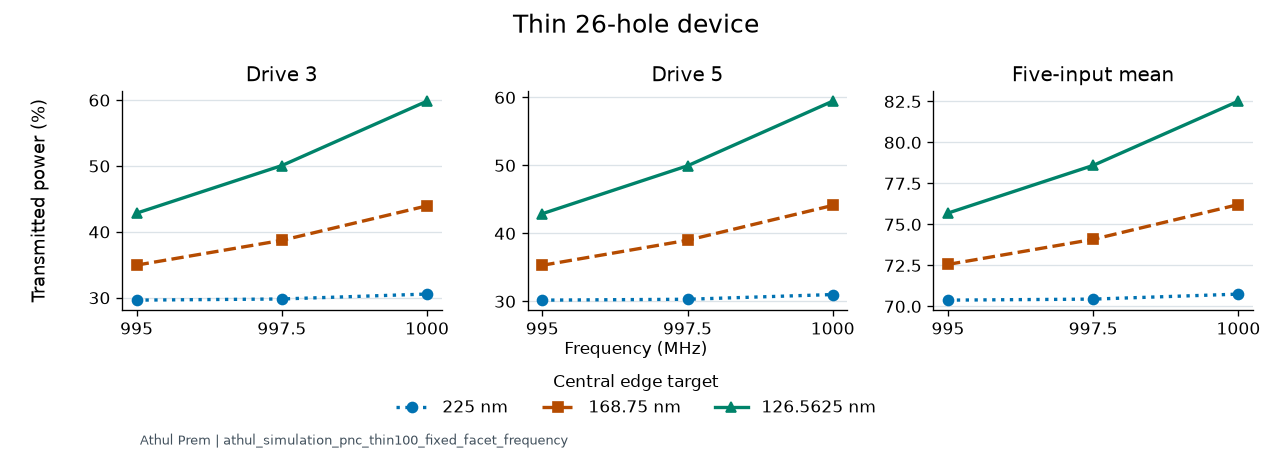

In [4]:
from hashlib import sha256
from pathlib import Path
import csv
import io
import json
import math
import matplotlib.pyplot as plt

record_path = Path("verification/thin_mesh_frequency_AP_pnc.json")
working_dir = Path.cwd()
for folder in (working_dir, *working_dir.parents):
    if (folder / record_path).is_file():
        project_root = folder
        mesh_frequency = json.loads((project_root / record_path).read_bytes())
        break
else:
    raise FileNotFoundError(f"Open the notebook inside the project to load {record_path}.")

frequencies_hz = mesh_frequency["frequencies_hz"]
central_edges_nm = mesh_frequency["central_max_edges_nm"]
levels = mesh_frequency["mesh_levels"]
if (
    mesh_frequency["status"] != "compared_saved_thin_mesh_frequency"
    or mesh_frequency["physical_thickness_nm"] != 100
    or mesh_frequency["thickness_layers"] != 2
    or mesh_frequency["circle_resolution"] != 32
    or mesh_frequency["reference_planes_x_m"] != [0.0, 16650e-9]
    or frequencies_hz != [995_000_000, 997_500_000, 1_000_000_000]
    or central_edges_nm != [225.0, 168.75, 126.5625]
    or [level["central_max_edge_nm"] for level in levels] != central_edges_nm
):
    raise ValueError("The compact record does not contain the declared fixed-facet mesh and frequency comparison.")

def read_coefficients(map_pin):
    publication = (project_root / map_pin["path"]).resolve()
    if not publication.is_relative_to(project_root):
        raise ValueError("The native map path escapes the project.")
    metadata = publication.read_bytes()
    if (len(metadata), sha256(metadata).hexdigest()) != (map_pin["bytes"], map_pin["sha256"]):
        raise ValueError(f"Native map identity differs at {publication}.")
    coefficient_name = "scattering_map_AP_pnc.csv"
    data = publication.with_name(coefficient_name).read_bytes()
    if sha256(data).hexdigest() != json.loads(metadata)["output_sha256"][coefficient_name]:
        raise ValueError(f"Native coefficient table differs at {publication.parent}.")
    return list(csv.DictReader(io.StringIO(data.decode("utf-8-sig"))))

def native_powers(rows, frequency_hz):
    blocks = {}
    for row in rows:
        if round(float(row["frequency_GHz"]) * 1e9) != frequency_hz:
            continue
        kind, incident, outgoing = (row["kind"], int(row["incident_port_index"]), int(row["outgoing_port_index"]))
        amplitude = complex(float(row["amplitude_real"]), float(row["amplitude_imag"]))
        power = float(row["power_fraction"])
        outputs = blocks.setdefault((kind, incident), {})
        if outgoing in outputs or power < 0 or not math.isclose(power, abs(amplitude)**2, rel_tol=5e-11, abs_tol=2e-15):
            raise ValueError("A saved complex coefficient or power is invalid or repeated.")
        outputs[outgoing] = power
    if len(blocks) != 10 or any(len(outputs) != 5 for outputs in blocks.values()):
        raise ValueError("Expected complete 5 by 5 native reflection and transmission blocks.")
    return {key: math.fsum(outputs.values()) for key, outputs in blocks.items()}

def mesh_transmissions(level, coefficient_cache):
    drives = {drive["reference_drive"]: drive["samples"] for drive in level["matched_drives"]}
    if set(drives) != set(range(1, 6)) or [point["frequency_hz"] for point in level["samples"]] != frequencies_hz:
        raise ValueError("Expected five matched native drives at all three frequencies.")
    displayed = [[], [], []]
    for index, point in enumerate(level["samples"]):
        frequency_hz = point["frequency_hz"]
        map_pin = point["archive"]["map"]
        if map_pin["path"] not in coefficient_cache:
            coefficient_cache[map_pin["path"]] = read_coefficients(map_pin)
        powers = native_powers(coefficient_cache[map_pin["path"]], frequency_hz)
        samples = {drive: samples[index] for drive, samples in drives.items()}
        for kind in ("reflection", "transmission"):
            totals = {}
            for drive, sample in samples.items():
                total = powers[kind, sample["native_root_id"]]
                if sample["frequency_hz"] != frequency_hz or not math.isclose(
                    total, sample[f"{kind}_fraction"], rel_tol=0, abs_tol=1e-10
                ):
                    raise ValueError("Native coefficient powers differ from the matched drive.")
                totals[drive] = total
            mean = math.fsum(totals.values()) / len(totals)
            saved_mean = level["equal_incoherent_mean"]["samples"][index]
            if saved_mean["frequency_hz"] != frequency_hz or not math.isclose(
                mean, saved_mean[f"{kind}_fraction"], rel_tol=0, abs_tol=1e-10
            ):
                raise ValueError("Native coefficient powers differ from the equal-incoherent mean.")
            if kind == "transmission":
                for values, fraction in zip(displayed, (totals[3], totals[5], mean), strict=True):
                    values.append(100 * fraction)
    return displayed

frequencies_mhz = [frequency / 1e6 for frequency in frequencies_hz]
styles = (
    {"color": "#0072B2", "marker": "o", "linestyle": ":"},
    {"color": "#B54B00", "marker": "s", "linestyle": "--"},
    {"color": "#00836A", "marker": "^", "linestyle": "-"},
)
coefficient_cache = {}
fig, axes = plt.subplots(1, 3, figsize=(10.6, 3.8))
for edge_nm, level, style in zip(central_edges_nm, levels, styles, strict=True):
    for ax, values in zip(axes, mesh_transmissions(level, coefficient_cache), strict=True):
        ax.plot(frequencies_mhz, values, label=f"{edge_nm:.8g} nm",
                linewidth=2, markersize=6, **style)

for ax, title in zip(axes, ("Drive 3", "Drive 5", "Five-input mean"), strict=True):
    ax.set_title(title, fontsize=12)
    ax.set_xticks(frequencies_mhz, [f"{frequency:g}" for frequency in frequencies_mhz])
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#dce3e8")
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Thin 26-hole device", y=0.97, fontsize=15)
fig.supylabel("Transmitted power (%)", x=0.024, y=0.56, fontsize=11)
fig.supxlabel("Frequency (MHz)", y=0.215, fontsize=10)
fig.legend(*axes[0].get_legend_handles_labels(), title="Central edge target", ncols=3,
           loc="lower center", bbox_to_anchor=(0.5, 0.054), frameon=False)
fig.text(0.11, 0.025, "Athul Prem | athul_simulation_pnc_thin100_fixed_facet_frequency",
         fontsize=8, color="#41505c")
fig.subplots_adjust(left=0.096, right=0.985, top=0.80, bottom=0.32, wspace=0.27)

row_count = sum(len(rows) for rows in coefficient_cache.values())
if (len(coefficient_cache), row_count) != (6, 450):
    raise ValueError("Expected 450 complex coefficients in the six native map tables.")
print(f"Verified {row_count} complex coefficient rows from {len(coefficient_cache)} native maps.")

gates = [gate for increment in mesh_frequency["spatial_increments"] for gate in increment["transmission_gates"]]
limit_pp = 100 * mesh_frequency["spatial_transmission_limit_fraction"]
passed = sum(gate["all_drives_passed"] for gate in gates)
worst_pp = 100 * max(gate["maximum_absolute_transmission_change_fraction"] for gate in gates)
print(f"Spatial transmission limit {limit_pp:g} percentage point per drive. "
      f"{passed} of {len(gates)} adjacent-mesh comparisons pass across all five drives. "
      f"The largest observed drive change is {worst_pp:.3f} percentage points.")
complex_limit = mesh_frequency["spatial_complex_amplitude_limit"]
complex_passed = sum(gate["all_drives_complex_amplitude_passed"] for gate in gates)
worst_complex = max(gate["maximum_absolute_complex_amplitude_change"] for gate in gates)
print(f"Complex-amplitude limit {complex_limit:g} per coefficient. "
      f"{complex_passed} of {len(gates)} comparisons pass across both scattering blocks. "
      f"The largest observed coefficient change is {worst_complex:.3f}.")
plt.show()
